## 1. Setup

In [6]:
from pathlib import Path
import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.transforms import functional as TF

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
LEARNING_RATE = 0.001

DATA_DIR = Path("road_dataset_224")
CLASS_TO_IDX = {"Normal": 0, "Damaged": 1}
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

for split in ["train", "val", "test"]:
    if not (DATA_DIR / split).exists():
        raise FileNotFoundError(f"Missing folder: {DATA_DIR / split}")

from torchvision import models
from torchvision.models import MobileNet_V2_Weights

RESULTS_DIR = Path("results/mobilenetv2")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = RESULTS_DIR / "best_mobilenetv2.pth"

Device: cpu


## 2. Dataset and Class Weights

In [7]:
base_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

def remap_labels(dataset):
    dataset.samples = [
        (path, CLASS_TO_IDX[Path(path).parent.name])
        for path, _ in dataset.samples
    ]
    dataset.imgs = dataset.samples
    dataset.targets = [label for _, label in dataset.samples]
    dataset.class_to_idx = CLASS_TO_IDX.copy()
    dataset.classes = ["Normal", "Damaged"]
    return dataset

def load_split(split, transform):
    dataset = datasets.ImageFolder(DATA_DIR / split, transform=transform)
    return remap_labels(dataset)

train_dataset = load_split("train", base_transform)
val_dataset = load_split("val", base_transform)
test_dataset = load_split("test", base_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

for name, dataset in [("Train", train_dataset), ("Validation", val_dataset), ("Test", test_dataset)]:
    counts = np.bincount(dataset.targets, minlength=2)
    print(f"{name}: Normal={counts[0]}, Damaged={counts[1]}, Total={len(dataset)}")

train_counts = np.bincount(train_dataset.targets, minlength=2)
class_weights = torch.tensor(
    len(train_dataset) / (2.0 * train_counts),
    dtype=torch.float32,
    device=device
)
print(f"Class weights -> Normal: {class_weights[0]:.4f}, Damaged: {class_weights[1]:.4f}")

Train: Normal=928, Damaged=2470, Total=3398
Validation: Normal=198, Damaged=529, Total=727
Test: Normal=200, Damaged=531, Total=731
Class weights -> Normal: 1.8308, Damaged: 0.6879


## 3. MobileNetV2 Transfer Learning Model

In [8]:
pretrained_weights = MobileNet_V2_Weights.IMAGENET1K_V1
model = models.mobilenet_v2(weights=pretrained_weights)

for parameter in model.features.parameters():
    parameter.requires_grad = False

in_features = model.classifier[1].in_features
model.classifier = nn.Sequential(
    nn.Dropout(0.2),
    nn.Linear(in_features, 2)
)
model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model.classifier)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

Sequential(
  (0): Dropout(p=0.2, inplace=False)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)
Total parameters: 2,226,434
Trainable parameters: 2,562


## 4. Training and Validation

Epoch 01/15 | Train Loss: 0.3717 | Val Loss: 0.2806
Epoch 02/15 | Train Loss: 0.2658 | Val Loss: 0.2190
Epoch 03/15 | Train Loss: 0.2489 | Val Loss: 0.2149
Epoch 04/15 | Train Loss: 0.2283 | Val Loss: 0.2279
Epoch 05/15 | Train Loss: 0.2201 | Val Loss: 0.2001
Epoch 06/15 | Train Loss: 0.2056 | Val Loss: 0.2602
Epoch 07/15 | Train Loss: 0.2009 | Val Loss: 0.2320
Epoch 08/15 | Train Loss: 0.1995 | Val Loss: 0.2017
Epoch 09/15 | Train Loss: 0.1937 | Val Loss: 0.1874
Epoch 10/15 | Train Loss: 0.1880 | Val Loss: 0.1881
Epoch 11/15 | Train Loss: 0.1863 | Val Loss: 0.1816
Epoch 12/15 | Train Loss: 0.1823 | Val Loss: 0.1695
Epoch 13/15 | Train Loss: 0.1863 | Val Loss: 0.1728
Epoch 14/15 | Train Loss: 0.1841 | Val Loss: 0.2018
Epoch 15/15 | Train Loss: 0.1793 | Val Loss: 0.1980

Best epoch: 12 | Best validation loss: 0.1695


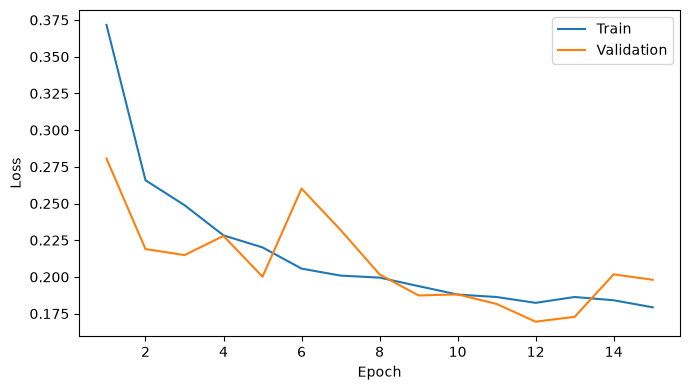

In [9]:
history = []
best_val_loss = float("inf")
best_epoch = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    model.features.eval()  # Keep the frozen pretrained backbone fully fixed.
    train_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = criterion(model(images), labels)
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            val_loss += criterion(model(images), labels).item()

    train_loss /= len(train_loader)
    val_loss /= len(val_loader)
    history.append({"Epoch": epoch, "Train Loss": train_loss, "Validation Loss": val_loss})

    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        torch.save(model.state_dict(), BEST_MODEL_PATH)

    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

print(f"\nBest epoch: {best_epoch} | Best validation loss: {best_val_loss:.4f}")

history_df = pd.DataFrame(history)
history_df.to_csv(RESULTS_DIR / "training_history.csv", index=False)

plt.figure(figsize=(7, 4))
plt.plot(history_df["Epoch"], history_df["Train Loss"], label="Train")
plt.plot(history_df["Epoch"], history_df["Validation Loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "loss_curve.png", dpi=200)
plt.show()

## 5. Final Test Evaluation


Final Test Results
Accuracy: 0.9289
Precision: 0.9669
Recall: 0.9341
F1: 0.9502

Classification Report:
              precision    recall  f1-score   support

      Normal       0.84      0.92      0.88       200
     Damaged       0.97      0.93      0.95       531

    accuracy                           0.93       731
   macro avg       0.90      0.92      0.91       731
weighted avg       0.93      0.93      0.93       731



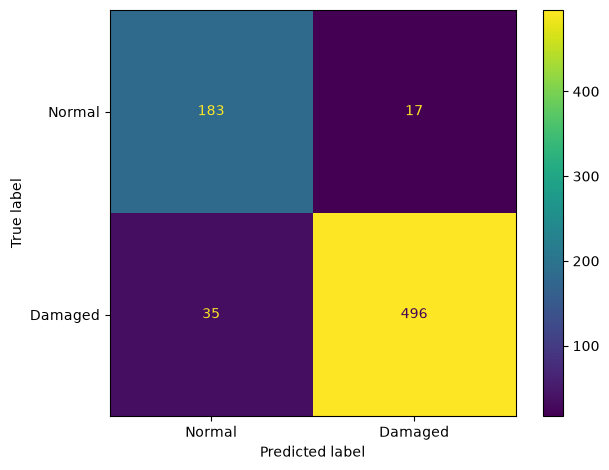

In [10]:
def evaluate(model, loader):
    y_true, y_pred = [], []

    model.eval()
    with torch.no_grad():
        for images, labels in loader:
            outputs = model(images.to(device))
            predictions = outputs.argmax(dim=1).cpu().numpy()
            y_pred.extend(predictions)
            y_true.extend(labels.numpy())

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }
    return metrics, np.array(y_true), np.array(y_pred)

def robustness_transform(brightness=1.0, blur=None):
    steps = [transforms.Resize((224, 224))]

    if brightness != 1.0:
        steps.append(transforms.Lambda(lambda img, f=brightness: TF.adjust_brightness(img, f)))

    if blur is not None:
        kernel_size, sigma = blur
        steps.append(transforms.GaussianBlur(kernel_size=kernel_size, sigma=sigma))

    steps += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    return transforms.Compose(steps)

ROBUSTNESS_CONDITIONS = {
    "Clean": {"brightness": 1.0, "blur": None},
    "Low Brightness (0.7)": {"brightness": 0.7, "blur": None},
    "High Brightness (1.3)": {"brightness": 1.3, "blur": None},
    "Mild Blur (k=5, sigma=1.0)": {"brightness": 1.0, "blur": (5, 1.0)},
    "Strong Blur (k=9, sigma=2.0)": {"brightness": 1.0, "blur": (9, 2.0)}
}

def run_robustness(model):
    rows = []
    for condition, settings in ROBUSTNESS_CONDITIONS.items():
        dataset = load_split("test", robustness_transform(**settings))
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        metrics, _, _ = evaluate(model, loader)
        rows.append({"Condition": condition, **metrics})
    return pd.DataFrame(rows)

model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
test_metrics, y_true, y_pred = evaluate(model, test_loader)

print("\nFinal Test Results")
for name, value in test_metrics.items():
    print(f"{name}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Normal", "Damaged"],
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["Normal", "Damaged"]).plot(values_format="d")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=200)
plt.show()

pd.DataFrame([test_metrics]).to_csv(RESULTS_DIR / "clean_test_metrics.csv", index=False)

## 6. Robustness Evaluation

In [11]:
robustness_results = run_robustness(model)
robustness_results.to_csv(RESULTS_DIR / "robustness_results.csv", index=False)

print(robustness_results.to_string(
    index=False,
    formatters={c: "{:.4f}".format for c in ["Accuracy", "Precision", "Recall", "F1"]}
))

                   Condition Accuracy Precision Recall     F1
                       Clean   0.9289    0.9669 0.9341 0.9502
        Low Brightness (0.7)   0.9275    0.9780 0.9209 0.9486
       High Brightness (1.3)   0.9193    0.9436 0.9454 0.9445
  Mild Blur (k=5, sigma=1.0)   0.8304    0.9657 0.7947 0.8719
Strong Blur (k=9, sigma=2.0)   0.7880    0.9273 0.7684 0.8404
